In [1]:
%pip install pandas seaborn matplotlib scikit-learn

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

# Set the graph style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load the Iris dataset
iris = load_iris(as_frame=True)

# Create a DataFrame
df = iris.frame

# Replace numeric flower labels with flower names
df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

# Rename columns to make them easier to read
df = df.rename(columns={
    "sepal length (cm)": "sepal_length",
    "sepal width (cm)": "sepal_width",
    "petal length (cm)": "petal_length",
    "petal width (cm)": "petal_width"
})

# Display the first five rows
print(df.head())

   sepal_length  sepal_width  petal_length  petal_width  target species
0           5.1          3.5           1.4          0.2       0  setosa
1           4.9          3.0           1.4          0.2       0  setosa
2           4.7          3.2           1.3          0.2       0  setosa
3           4.6          3.1           1.5          0.2       0  setosa
4           5.0          3.6           1.4          0.2       0  setosa


In [4]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

print("\nSpecies counts:")
print(df["species"].value_counts())

Dataset shape: (150, 6)

Column names:
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'target',
       'species'],
      dtype='object')

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
target          0
species         0
dtype: int64

Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


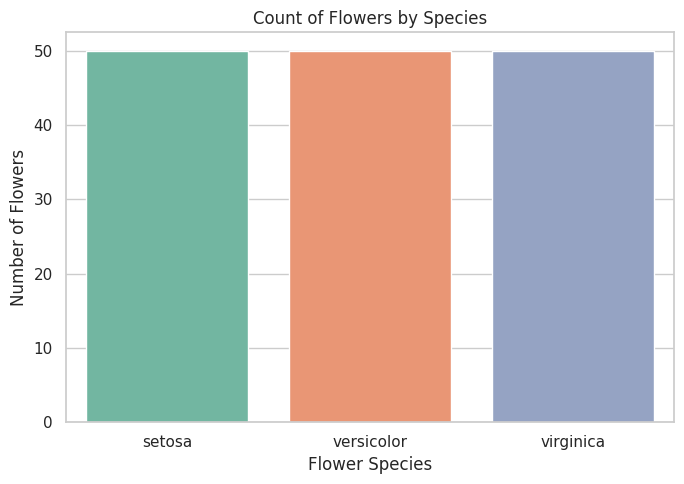

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="species", hue="species",
              palette="Set2", legend=False)

plt.title("Count of Flowers by Species")
plt.xlabel("Flower Species")
plt.ylabel("Number of Flowers")
plt.tight_layout()
plt.show()

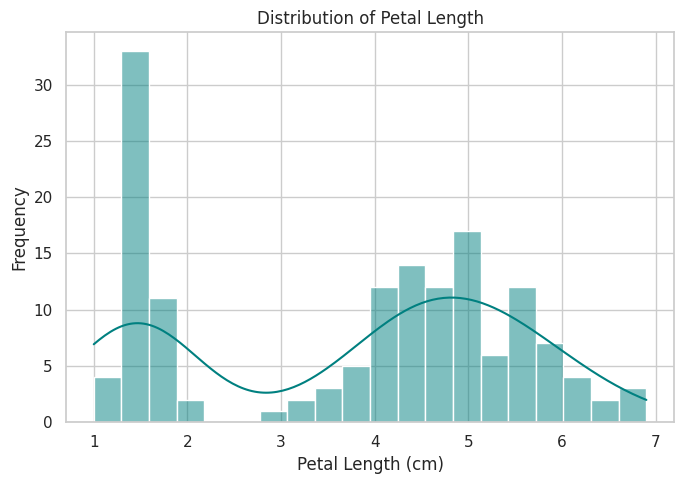

In [6]:
plt.figure(figsize=(7, 5))

sns.histplot(data=df, x="petal_length",
             bins=20, kde=True, color="teal")

plt.title("Distribution of Petal Length")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

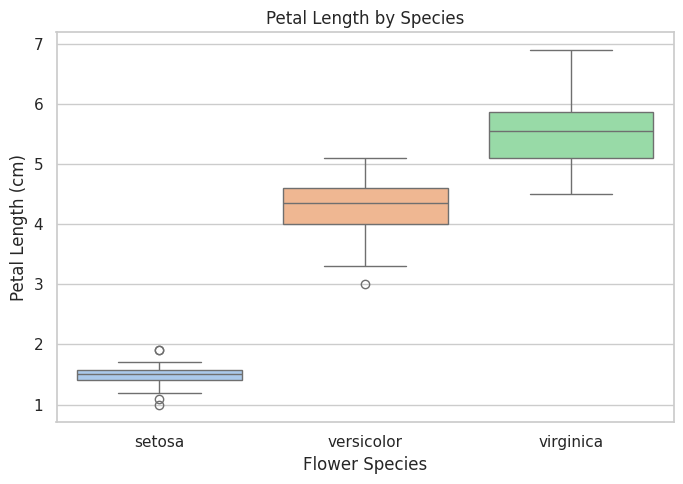

In [7]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="species", y="petal_length",
            hue="species", palette="pastel", legend=False)

plt.title("Petal Length by Species")
plt.xlabel("Flower Species")
plt.ylabel("Petal Length (cm)")
plt.tight_layout()
plt.show()

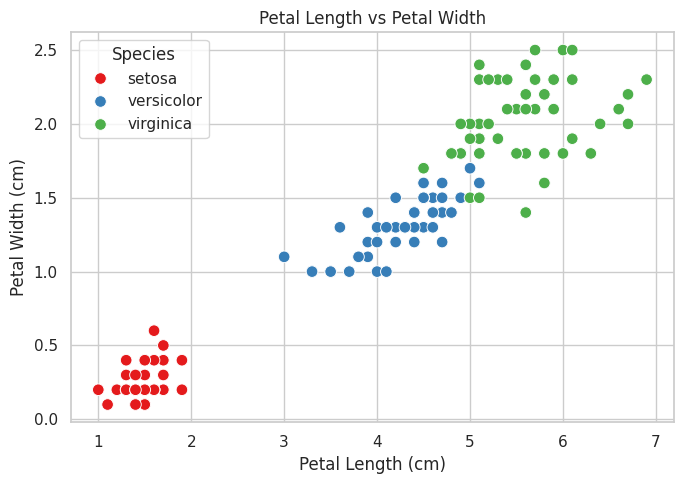

In [8]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="petal_length",
    y="petal_width",
    hue="species",
    s=70,
    palette="Set1"
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend(title="Species")
plt.tight_layout()
plt.show()

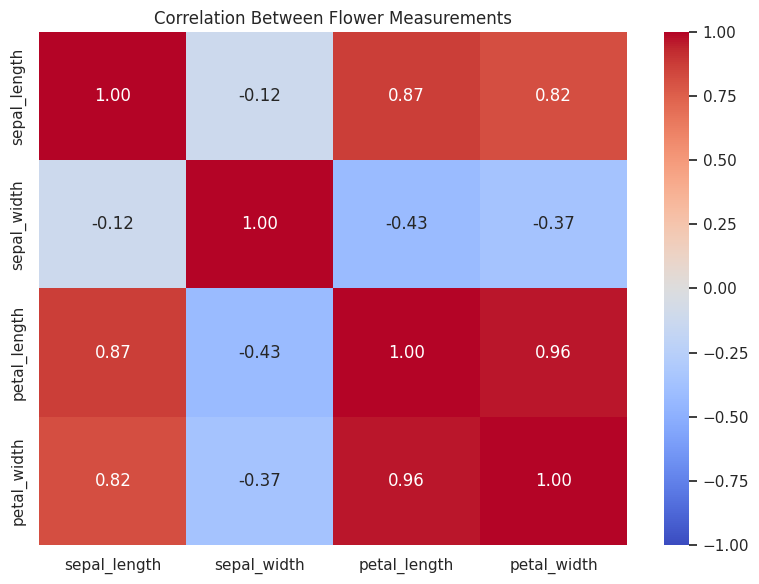

In [9]:
# Select numerical measurement columns only
measurements = df[
    ["sepal_length", "sepal_width",
     "petal_length", "petal_width"]
]

# Calculate correlations
correlation = measurements.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Flower Measurements")
plt.tight_layout()
plt.show()

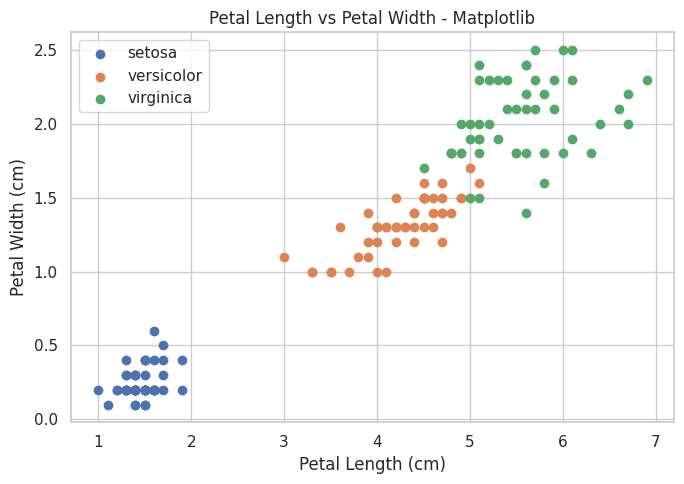

In [10]:
plt.figure(figsize=(7, 5))

for species in df["species"].unique():
    subset = df[df["species"] == species]

    plt.scatter(
        subset["petal_length"],
        subset["petal_width"],
        label=species
    )

plt.title("Petal Length vs Petal Width - Matplotlib")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()